In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
file_path="/content/drive/MyDrive/Shopify.csv"

In [3]:
import pandas as pd
df = pd.read_csv(file_path)
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2015-05-20,17.000000,17.000000,17.000000,17.000000,17.000000,0
1,2015-05-21,28.000000,28.740000,24.110001,25.680000,25.680000,12303900
2,2015-05-22,26.070000,31.100000,26.000000,28.309999,28.309999,2841200
3,2015-05-26,29.799999,30.340000,29.080000,29.650000,29.650000,820200
4,2015-05-27,30.670000,30.809999,27.000000,27.500000,27.500000,797600


In [4]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Shape: (1766, 7)

Columns:
Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], dtype='object')

Data Types:
Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object

Missing Values:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


In [5]:
df['Date'] = pd.to_datetime(df['Date'], utc=True)
df = df.sort_values('Date')
df = df.dropna()
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2015-05-20 00:00:00+00:00,17.000000,17.000000,17.000000,17.000000,17.000000,0
1,2015-05-21 00:00:00+00:00,28.000000,28.740000,24.110001,25.680000,25.680000,12303900
2,2015-05-22 00:00:00+00:00,26.070000,31.100000,26.000000,28.309999,28.309999,2841200
3,2015-05-26 00:00:00+00:00,29.799999,30.340000,29.080000,29.650000,29.650000,820200
4,2015-05-27 00:00:00+00:00,30.670000,30.809999,27.000000,27.500000,27.500000,797600


In [6]:
df['Date'] = pd.to_datetime(df['Date'], utc=True)
df = df.sort_values('Date')
df = df.dropna()
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2015-05-20 00:00:00+00:00,17.000000,17.000000,17.000000,17.000000,17.000000,0
1,2015-05-21 00:00:00+00:00,28.000000,28.740000,24.110001,25.680000,25.680000,12303900
2,2015-05-22 00:00:00+00:00,26.070000,31.100000,26.000000,28.309999,28.309999,2841200
3,2015-05-26 00:00:00+00:00,29.799999,30.340000,29.080000,29.650000,29.650000,820200
4,2015-05-27 00:00:00+00:00,30.670000,30.809999,27.000000,27.500000,27.500000,797600


In [8]:
df['Date'] = pd.to_datetime(df['Date'], utc=True)
df = df.sort_values('Date')
df = df.dropna()
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2015-05-20 00:00:00+00:00,17.000000,17.000000,17.000000,17.000000,17.000000,0
1,2015-05-21 00:00:00+00:00,28.000000,28.740000,24.110001,25.680000,25.680000,12303900
2,2015-05-22 00:00:00+00:00,26.070000,31.100000,26.000000,28.309999,28.309999,2841200
3,2015-05-26 00:00:00+00:00,29.799999,30.340000,29.080000,29.650000,29.650000,820200
4,2015-05-27 00:00:00+00:00,30.670000,30.809999,27.000000,27.500000,27.500000,797600


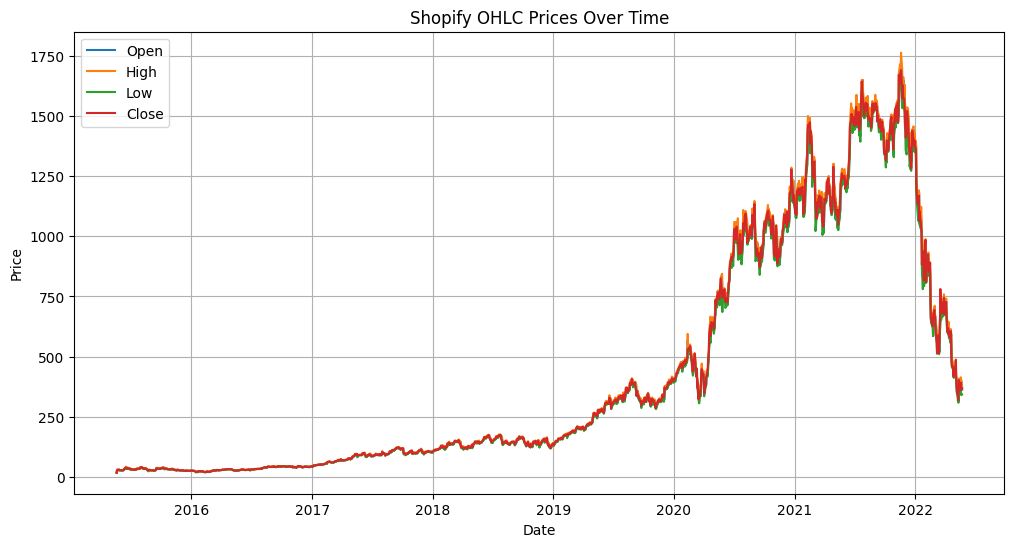

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(df['Date'], df['Open'], label='Open')
plt.plot(df['Date'], df['High'], label='High')
plt.plot(df['Date'], df['Low'], label='Low')
plt.plot(df['Date'], df['Close'], label='Close')
plt.title('Shopify OHLC Prices Over Time')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid()
plt.show()

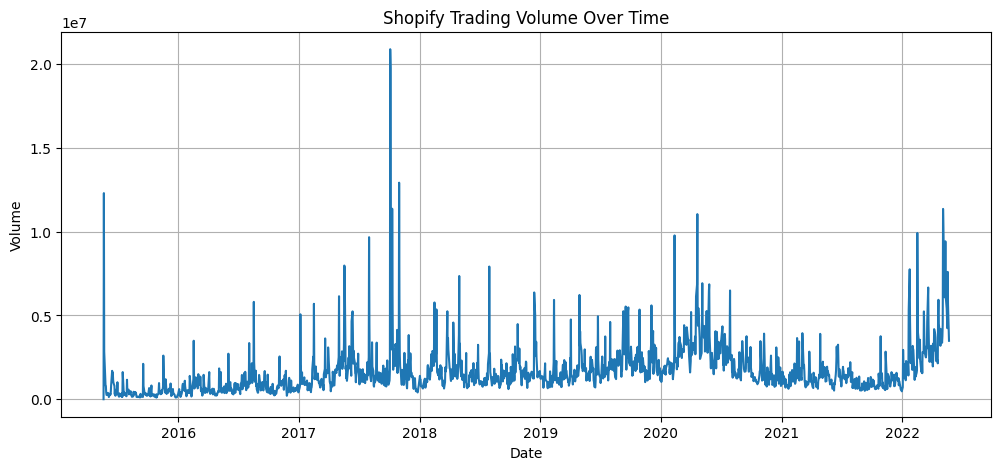

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(df['Date'], df['Volume'])
plt.title('Shopify Trading Volume Over Time')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.grid()
plt.show()

In [14]:
df['Daily_Return'] = df['Close'].pct_change() * 100
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume,Daily_Return
0,2015-05-20 00:00:00+00:00,17.000000,17.000000,17.000000,17.000000,17.000000,0,NaN
1,2015-05-21 00:00:00+00:00,28.000000,28.740000,24.110001,25.680000,25.680000,12303900,51.058824
2,2015-05-22 00:00:00+00:00,26.070000,31.100000,26.000000,28.309999,28.309999,2841200,10.241429
3,2015-05-26 00:00:00+00:00,29.799999,30.340000,29.080000,29.650000,29.650000,820200,4.733313
4,2015-05-27 00:00:00+00:00,30.670000,30.809999,27.000000,27.500000,27.500000,797600,-7.251265


In [15]:
df['MA_20'] = df['Close'].rolling(window=20).mean()

In [16]:
df['MA_50'] = df['Close'].rolling(window=50).mean()

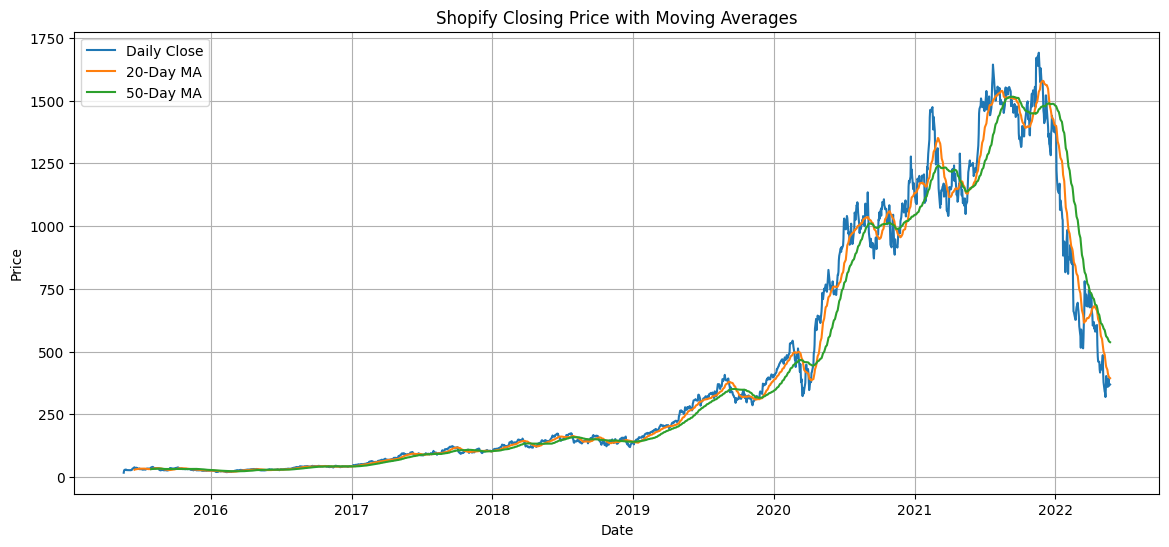

In [17]:
plt.figure(figsize=(14, 6))
plt.plot(df['Date'], df['Close'], label='Daily Close')
plt.plot(df['Date'], df['MA_20'], label='20-Day MA')
plt.plot(df['Date'], df['MA_50'], label='50-Day MA')
plt.title('Shopify Closing Price with Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid()
plt.show()

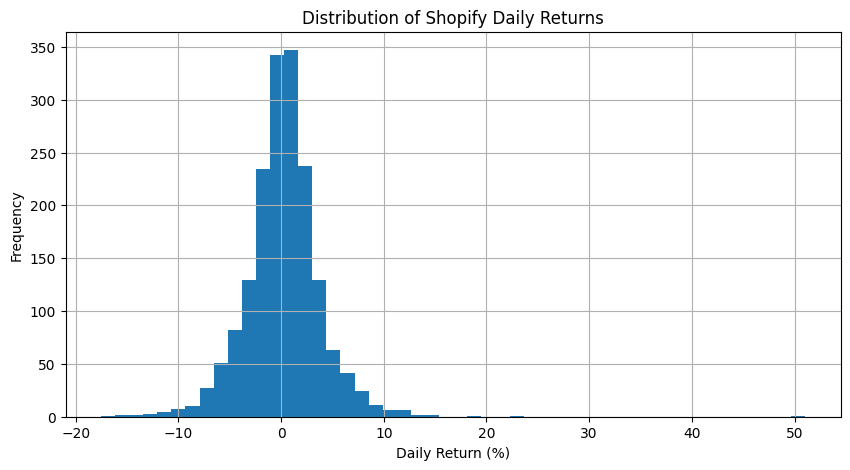

In [18]:
plt.figure(figsize=(10, 5))
plt.hist(
    df['Daily_Return'].dropna(),
    bins=50
)
plt.title('Distribution of Shopify Daily Returns')
plt.xlabel('Daily Return (%)')
plt.ylabel('Frequency')
plt.grid()
plt.show()

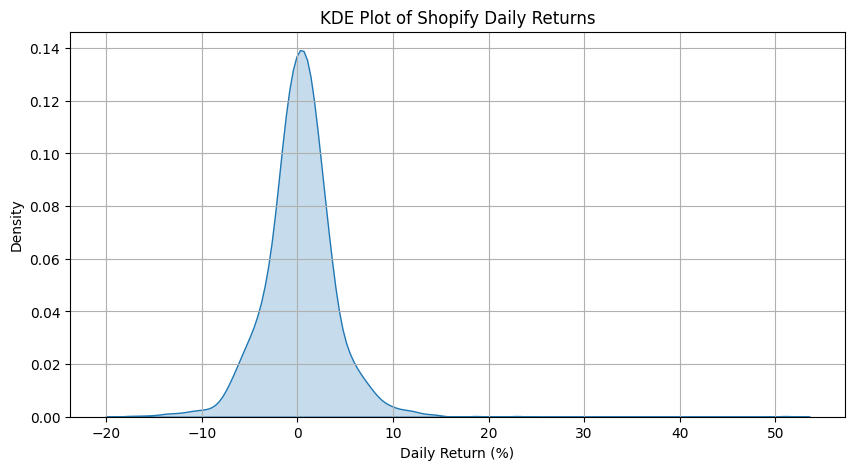

In [19]:
import seaborn as sns
plt.figure(figsize=(10, 5))
sns.kdeplot(
    df['Daily_Return'].dropna(),
    fill=True
)
plt.title('KDE Plot of Shopify Daily Returns')
plt.xlabel('Daily Return (%)')
plt.ylabel('Density')
plt.grid()
plt.show()

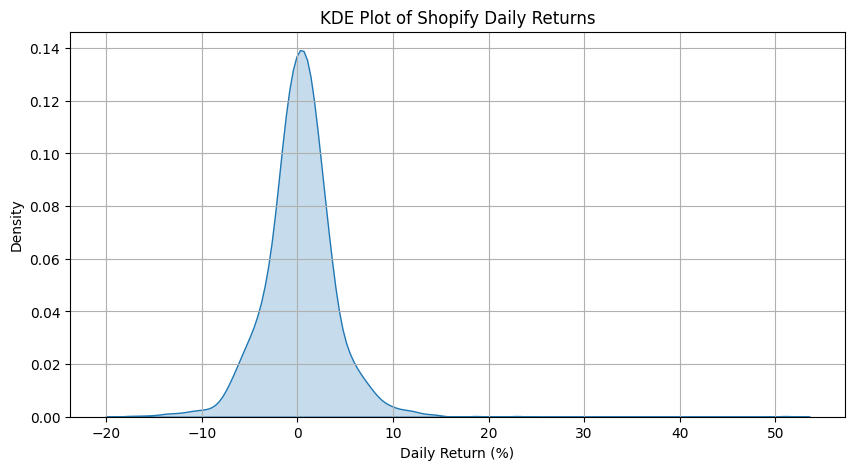

In [20]:
import seaborn as sns
plt.figure(figsize=(10, 5))
sns.kdeplot(
    df['Daily_Return'].dropna(),
    fill=True
)
plt.title('KDE Plot of Shopify Daily Returns')
plt.xlabel('Daily Return (%)')
plt.ylabel('Density')
plt.grid()
plt.show()

In [21]:
volatility = df['Daily_Return'].std()
print("Daily Volatility:", volatility, "%")

Daily Volatility: 3.7923619169175873 %


In [23]:
mean_return = df['Daily_Return'].mean()
std_return = df['Daily_Return'].std()
high_volatility = df[
    abs(df['Daily_Return'] - mean_return) > 2 * std_return
]
print(high_volatility[
    ['Date', 'Close', 'Daily_Return']
])

                          Date       Close  Daily_Return
1    2015-05-21 00:00:00+00:00   25.680000     51.058824
2    2015-05-22 00:00:00+00:00   28.309999     10.241429
15   2015-06-11 00:00:00+00:00   30.730000      9.359431
16   2015-06-12 00:00:00+00:00   33.630001      9.437035
20   2015-06-18 00:00:00+00:00   35.549999     -7.973083
...                        ...         ...           ...
1755 2022-05-09 00:00:00+00:00  340.040009     -9.920788
1758 2022-05-12 00:00:00+00:00  353.510010     10.960801
1759 2022-05-13 00:00:00+00:00  402.480011     13.852508
1760 2022-05-16 00:00:00+00:00  359.950012    -10.566984
1763 2022-05-19 00:00:00+00:00  391.329987      8.515887

[77 rows x 3 columns]


In [24]:
highest_gain = df.loc[
    df['Daily_Return'].idxmax()
]
highest_loss = df.loc[
    df['Daily_Return'].idxmin()
]
print("Highest Gain:")
print(highest_gain[['Date', 'Daily_Return']])
print("\nHighest Loss:")
print(highest_loss[['Date', 'Daily_Return']])

Highest Gain:
Date            2015-05-21 00:00:00+00:00
Daily_Return                    51.058824
Name: 1, dtype: object

Highest Loss:
Date            2020-03-16 00:00:00+00:00
Daily_Return                     -17.5518
Name: 1213, dtype: object


In [26]:
print("===== SHOPIFY STOCK FINANCIAL SUMMARY ====")
print("Start Date:", df['Date'].min())
print("End Date:", df['Date'].max())
print("Starting Price:", df['Close'].iloc[0])
print("Ending Price:", df['Close'].iloc[-1])
print("Highest Price:", df['High'].max())
print("Lowest Price:", df['Low'].min())
print("Average Closing Price:", df['Close'].mean())
print("Average Daily Return:", df['Daily_Return'].mean(), "%")
print("Daily Volatility:", df['Daily_Return'].std(), "%")
print("Number of High-Volatility Days:", len(high_volatility))

===== SHOPIFY STOCK FINANCIAL SUMMARY ====
Start Date: 2015-05-20 00:00:00+00:00
End Date: 2022-05-23 00:00:00+00:00
Starting Price: 17.0
Ending Price: 368.48999
Highest Price: 1762.917969
Lowest Price: 17.0
Average Closing Price: 426.2056005945639
Average Daily Return: 0.24450494868283582 %
Daily Volatility: 3.7923619169175873 %
Number of High-Volatility Days: 77
